In [63]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from sklearn.model_selection import train_test_split

In [64]:
PATH = "./Dataset"
x = []
y = []
counter = 0

img_row, img_col = 224, 224

CLASS_NAMES = os.listdir(PATH)
print(CLASS_NAMES)

['Broccoli', 'Carrot', 'Cucumber', 'Tomato']


In [65]:
for class_path in os.listdir(PATH):
    for img_path in os.listdir(f"{PATH}/{class_path}"):
        full_img_path = f"{PATH}/{class_path}/{img_path}"
        label = counter

        image = tf.keras.preprocessing.image.load_img(full_img_path, target_size=(img_row, img_col), color_mode="grayscale")
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(label)
    counter += 1

x = np.array(x)
y = np.array(y)

# random shuffle
idx = np.random.permutation(len(x))
x, y = x[idx], y[idx] 

In [66]:
x = x.astype('float32') / 255.0

In [67]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=32)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=32)

In [68]:
y_train = keras.utils.to_categorical(y_train, num_classes=4)
y_val = keras.utils.to_categorical(y_val, num_classes=4)
y_test = keras.utils.to_categorical(y_test, num_classes=4)

print(x_train.shape)

(1600, 224, 224, 1)


In [69]:
model = keras.Sequential([
    keras.layers.Conv2D(6, (5,5), activation='relu', input_shape=(img_row, img_col, 1)),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(16, (5,5), activation='relu'),
    keras.layers.Conv2D(16, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Flatten(),

    keras.layers.Dense(120, activation='relu'),
    keras.layers.Dense(4, activation='softmax')
])

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 220, 220, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 110, 110, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 106, 106, 16)   │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 120)            │     4,994,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           484 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,003,512 (19.09 MB)

 Trainable params: 5,003,512 (19.09 MB)

 Non-trainable params: 0 (0.00 B)

In [70]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [71]:
history = model.fit(x_train, y_train, batch_size=120, epochs=10, validation_data=(x_val, y_val))

Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 366ms/step - accuracy: 0.2544 - loss: 1.7242 - val_accuracy: 0.2300 - val_loss: 1.3268
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 343ms/step - accuracy: 0.3400 - loss: 1.2554 - val_accuracy: 0.5250 - val_loss: 1.1999
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 405ms/step - accuracy: 0.5838 - loss: 0.9902 - val_accuracy: 0.5900 - val_loss: 0.9496
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 6s 408ms/step - accuracy: 0.6769 - loss: 0.7599 - val_accuracy: 0.6800 - val_loss: 0.8295
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 369ms/step - accuracy: 0.7831 - loss: 0.5782 - val_accuracy: 0.7200 - val_loss: 0.7548
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 376ms/step - accuracy: 0.8119 - loss: 0.4815 - val_accuracy: 0.7500 - val_loss: 0.6095
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 334ms/step - accuracy: 0.8612 - loss: 0.3699 - val_accuracy: 0.8050 - val_loss: 0.5167
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 308ms/step - accuracy: 0.8913 - loss: 0.3062 - val_accuracy: 0.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


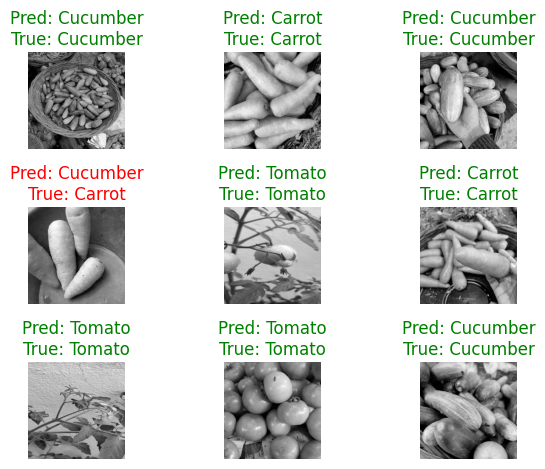

In [72]:
# predict data
predictions = model.predict(x_test)
true_label = np.argmax(y_test, axis=1)
predicted_label = np.argmax(predictions, axis=1)

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')

    color = 'green' if predicted_label[i] == true_label[i] else 'red'
    plt.title(f"Pred: {CLASS_NAMES[predicted_label[i]]}\nTrue: {CLASS_NAMES[true_label[i]]}", color=color)

plt.tight_layout()
plt.show()

In [73]:
for i, predict in enumerate(predictions):
    print(f"Actual: {CLASS_NAMES[true_label[i]]} | Prediction: {CLASS_NAMES[predicted_label[i]]}")

Actual: Cucumber | Prediction: Cucumber
Actual: Carrot | Prediction: Carrot
Actual: Cucumber | Prediction: Cucumber
Actual: Carrot | Prediction: Cucumber
Actual: Tomato | Prediction: Tomato
Actual: Carrot | Prediction: Carrot
Actual: Tomato | Prediction: Tomato
Actual: Tomato | Prediction: Tomato
Actual: Cucumber | Prediction: Cucumber
Actual: Tomato | Prediction: Carrot
Actual: Cucumber | Prediction: Cucumber
Actual: Cucumber | Prediction: Cucumber
Actual: Tomato | Prediction: Tomato
Actual: Carrot | Prediction: Carrot
Actual: Tomato | Prediction: Tomato
Actual: Carrot | Prediction: Carrot
Actual: Cucumber | Prediction: Cucumber
Actual: Carrot | Prediction: Carrot
Actual: Tomato | Prediction: Tomato
Actual: Broccoli | Prediction: Broccoli
Actual: Tomato | Prediction: Tomato
Actual: Carrot | Prediction: Carrot
Actual: Broccoli | Prediction: Cucumber
Actual: Carrot | Prediction: Carrot
Actual: Tomato | Prediction: Tomato
Actual: Cucumber | Prediction: Carrot
Actual: Carrot | Prediction:

In [74]:
score = model.evaluate(x_test, y_test)
print(f"acc: {score[1]}")
print(f"loss: {score[0]}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8450 - loss: 0.4813
acc: 0.8450000286102295
loss: 0.48131781816482544


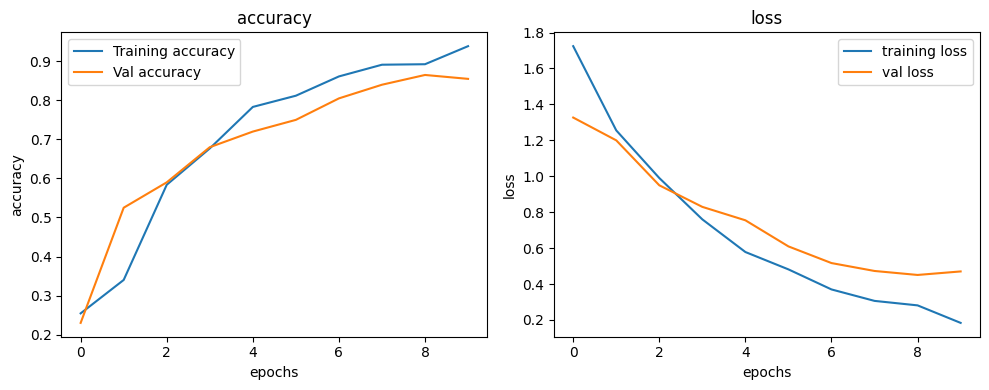

In [81]:
plt.figure(figsize=(10,4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Val accuracy')
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("accuracy")
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label="training loss")
plt.plot(history.history['val_loss'], label="val loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("loss")
plt.legend()

plt.tight_layout()
plt.show()